# 04 — Clustering: Discovering Data-Driven Player Archetypes

**Project:** Positionless NBA Player Archetypes · **Season:** 2025-26 · **Population:** 379 players with ≥ 500 minutes

The PCA notebook showed that player roles vary along at least three independent axes (interior ↔ perimeter,
on-ball creator ↔ off-ball finisher, disruptor ↔ scorer), while the five listed positions capture essentially only the
first. This notebook groups players **by what they do**, using two clustering algorithms built on different ideas of
what a "group" is:

| Method | Idea of a cluster | Needs in advance | Every player gets a cluster? |
|---|---|---|---|
| **k-means** (primary model) | A **centre** (centroid); each player belongs to the nearest one. The algorithm alternates between assigning players to the nearest centroid and moving each centroid to the mean of its players | the number of clusters *k* | **Yes**: even an unusual player is forced into the nearest group |
| **DBSCAN** (density-based perspective) | A **dense region**: players with at least `min_samples` neighbours within distance ε are *core points*; clusters are chains of overlapping core neighbourhoods | the radius ε and `min_samples` | **No**: players in sparse regions are labelled **noise** |

k-means answers *"which role is each player closest to?"*; DBSCAN answers *"where are the crowded regions of the
style space, and who lives outside them?"* Used together, they show both the archetypes and how sharply (or softly)
they are separated.

| § | Question |
|---|---|
| 1 | Load the feature matrix |
| 2 | How many clusters? Elbow (inertia), silhouette, bootstrap stability |
| 3 | Choosing *k*: statistics vs. usefulness (3 families, 8 archetypes) |
| 4 | The archetypes: centroid profiles, names, members, PCA map |
| 5 | How solid is each archetype? Silhouette plot and bootstrap Jaccard stability |
| 6 | Border players: who sits between two archetypes? |
| 7 | Are the k-means results robust to preprocessing choices? |
| 8 | DBSCAN: parameter sweep, dense cores vs. noise |
| 9 | Archetypes vs. listed positions, and export |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

warnings.filterwarnings('ignore', category=UserWarning)   # KMeans memory-leak notice on some platforms
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)
pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid', context='notebook')

DATA = Path('../data') if Path('../data').exists() else Path('data')
POS_ORDER = ['PG', 'SG', 'SF', 'PF', 'C']
SEED = 0

---
## 1. Load the Feature Matrix

**Goal.** Load the 13 power-transformed style features (the clustering input chosen in the PCA notebook), plus the raw
features (to describe clusters in real units) and the PCA scores (to draw clusters on the player map).

**Why the full 13 features rather than PCA scores?** Redundancy was already removed at feature selection (max VIF 8.8),
so the full matrix carries no duplicated information, and it keeps the 31% of variance outside PC1–PC3. Clustering on
PC scores is run as a robustness check in §7.

**What to look for.** The tables must be row-aligned (same players in the same order).

In [2]:
power = pd.read_csv(DATA / 'processed' / 'features_power.csv')
standard = pd.read_csv(DATA / 'processed' / 'features_standard.csv')
raw = pd.read_csv(DATA / 'processed' / 'features_raw.csv')
pcs = pd.read_csv(DATA / 'processed' / 'pca_scores.csv')

META = ['player_id', 'player', 'team', 'pos', 'pos_played', 'age', 'g', 'mp',
        'pg_percent', 'sg_percent', 'sf_percent', 'pf_percent', 'c_percent']
FEAT = [c for c in power.columns if c not in META]
assert all((t['player_id'] == power['player_id']).all() for t in (standard, raw, pcs))
X = power[FEAT].values
print('players:', X.shape[0], '| features:', X.shape[1])
print(FEAT)

players: 379 | features: 13
['x3p_ar', 'corner3_rate', 'mid_share', 'rim_share', 'f_tr', 'usg_percent', 'ast_percent', 'tov_percent', 'percent_assisted_x2p_fg', 'orb_percent', 'drb_percent', 'blk_percent', 'stl_percent']


---
## 2. How Many Clusters? Internal Validation Metrics for k-means

**Goal.** Run k-means for k = 2 … 12 and score each solution with three complementary criteria.

| Criterion | What it measures | Better when |
|---|---|---|
| **Inertia** (within-cluster sum of squared distances to the centroid) | How tight the clusters are | Lower, but it *always* falls as k grows, so look for an **elbow** rather than the minimum |
| **Silhouette** | For each player: s = (b − a) / max(a, b), where a = mean distance to the own cluster, b = mean distance to the nearest other cluster; averaged over players | Higher (1 = perfectly separated, 0 = on a border, < 0 = probably misassigned) |
| **Bootstrap stability** | Refit on 30 resampled versions of the league; Adjusted Rand Index (ARI) between original and resampled labels | Higher (1 = identical clusters every time) |

**Why three criteria?** Inertia cannot choose *k* by itself: more centroids always means every player is closer to
one, down to one player per cluster with inertia 0. Silhouette penalises over-splitting: when a natural group is cut in two, its members end up close to the
neighbouring cluster, so b shrinks and s falls.
Stability asks a separate question: would a slightly different season produce the same groups? A clustering that
changes completely under resampling describes noise, not archetypes.

**Implementation note.** k-means depends on its random starting centroids, so each fit is run with 50 different
initialisations (`n_init=50`) and the solution with the lowest inertia is kept.

**What to look for.** Whether the criteria agree on a best *k*, and how sharply quality falls as *k* increases.

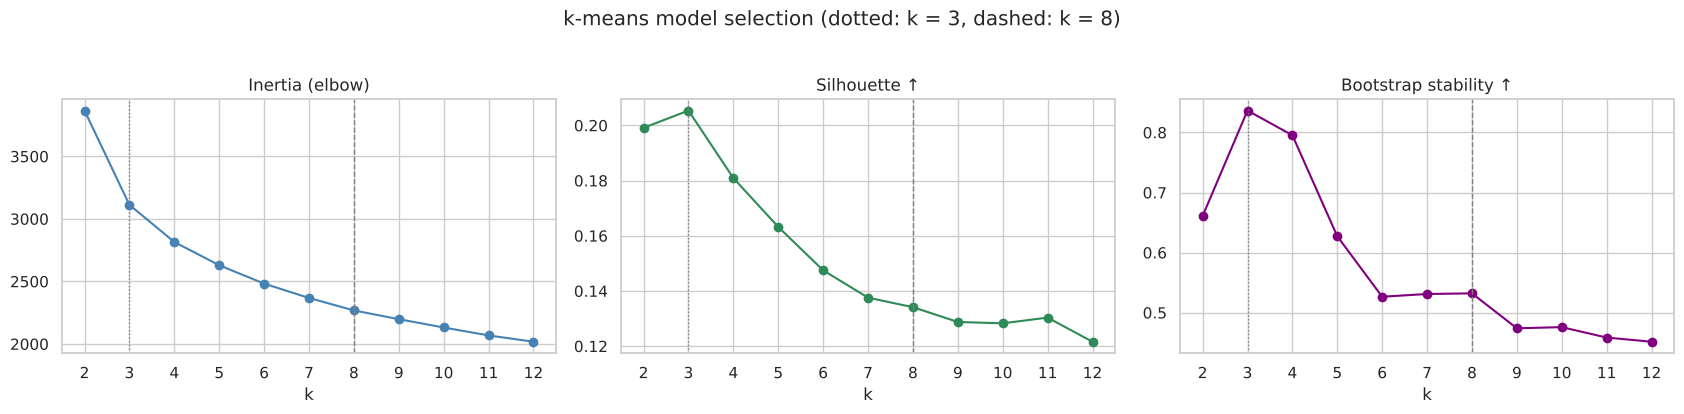

,inertia,silhouette,stability (bootstrap ARI),cluster sizes
k,,,,
2,3866.255,0.199,0.661,"[246, 133]"
3,3112.386,0.205,0.837,"[175, 132, 72]"
4,2815.547,0.181,0.795,"[132, 101, 90, 56]"
5,2629.435,0.163,0.627,"[110, 108, 79, 45, 37]"
6,2482.669,0.147,0.527,"[88, 82, 73, 54, 46, 36]"
7,2367.950,0.138,0.531,"[77, 64, 63, 59, 55, 33, 28]"
8,2268.173,0.134,0.532,"[61, 57, 56, 50, 48, 45, 31, 31]"
9,2198.242,0.129,0.474,"[61, 52, 48, 41, 40, 37, 36, 36, 28]"
10,2131.720,0.128,0.476,"[48, 48, 44, 39, 38, 38, 34, 33, 31, 26]"


In [3]:
K_RANGE = range(2, 13)
rng = np.random.default_rng(SEED)
rows, km_models = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    km_models[k] = km
    boot = []
    for b in range(30):
        idx = rng.choice(len(X), len(X), replace=True)
        boot.append(adjusted_rand_score(km.labels_, KMeans(n_clusters=k, n_init=10, random_state=b)
                                        .fit(X[idx]).predict(X)))
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X, km.labels_),
                 'stability (bootstrap ARI)': np.mean(boot),
                 'cluster sizes': sorted(np.bincount(km.labels_), reverse=True)})
metrics = pd.DataFrame(rows).set_index('k')

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
spec = [('inertia', 'Inertia (elbow)', 'steelblue'), ('silhouette', 'Silhouette ↑', 'seagreen'),
        ('stability (bootstrap ARI)', 'Bootstrap stability ↑', 'purple')]
for a, (col, title, c) in zip(ax, spec):
    a.plot(metrics.index, metrics[col], 'o-', color=c)
    a.axvline(3, color='grey', ls=':', lw=1); a.axvline(8, color='grey', ls='--', lw=1)
    a.set(title=title, xlabel='k', xticks=list(K_RANGE))
plt.suptitle('k-means model selection (dotted: k = 3, dashed: k = 8)', y=1.03)
plt.tight_layout(); plt.show()
metrics.round(3)

### Findings: Internal metrics
- **Both criteria that can choose k point to k = 3**: the highest silhouette (0.205) and the highest bootstrap
  stability (ARI ≈ 0.84).
- **The absolute silhouette values are low** (0.12–0.21 at every k). Values below about 0.25 mean the groups are not
  well separated: most players sit closer to a cluster border than to a cluster core. This is not a modelling failure. It
  is the main empirical finding of the EDA and PCA, seen from another angle: **NBA roles form a continuum, not
  islands.** Any clustering is a partition of a continuous space. DBSCAN (§8) confirms this independently.
- **Inertia has no sharp elbow.** The curve bends gently around k = 3–4, then keeps falling smoothly, which is again
  the signature of continuous structure.
- **Stability drops in two steps:** about 0.8 for k = 3–4, about 0.6 at k = 5, then a plateau around 0.45–0.53 from
  k = 6 to 12. Beyond k = 5, finer splits are reproducible only *partly*, and no particular k in 6–12 is clearly
  better than its neighbours.

---
## 3. Choosing *k*: What the Statistics Say vs. What the Project Needs

The metrics agree that the most *separated* and *stable* partition is **k = 3**. Before accepting it, it is worth
looking at what those three groups are.

**Goal.** Inspect the k = 3 solution in real units (cluster medians of the raw features).

**What to look for.** Whether three groups describe genuinely new roles, or mostly re-discover the traditional
guard / wing / big split.

In [4]:
lab3 = km_models[3].labels_
prof3 = raw[FEAT].groupby(lab3).median()
prof3.insert(0, 'players', np.bincount(lab3))
prof3[['PC1', 'PC2', 'PC3']] = pcs[['PC1', 'PC2', 'PC3']].groupby(lab3).mean()
display(prof3.round(2))
print('listed positions per cluster:')
pd.crosstab(lab3, power['pos'])[POS_ORDER]

,players,x3p_ar,corner3_rate,mid_share,rim_share,f_tr,usg_percent,ast_percent,tov_percent,percent_assisted_x2p_fg,orb_percent,drb_percent,blk_percent,stl_percent,PC1,PC2,PC3
0,175,0.54,0.17,0.07,0.20,0.20,16.50,10.3,11.20,0.65,4.2,12.50,1.40,1.6,-0.47,-1.49,0.04
1,132,0.40,0.07,0.18,0.17,0.28,23.65,22.6,12.75,0.39,2.7,12.05,1.00,1.7,-1.15,1.77,0.05
2,72,0.11,0.02,0.06,0.44,0.35,16.80,10.1,13.40,0.67,11.2,21.10,3.55,1.5,3.26,0.38,-0.20


listed positions per cluster:


pos,PG,SG,SF,PF,C
row_0,,,,,
0,13,62,41,50,9
1,54,38,24,9,7
2,1,1,3,15,52


**Reading the k = 3 solution.** The three groups are:
1. **Bigs** (72 players): rim share 0.44, ORB% 11, BLK% 3.6, high PC1.
2. **On-ball creators** (132): usage ≈ 24%, AST% ≈ 23%, high PC2.
3. **Off-ball perimeter players** (175): 3PA rate 0.54, corner-3 rate 0.17, about two-thirds of their 2s assisted,
   low PC2.

These are robust and meaningful, and already more informative than positions: group 2 (creators) cuts across PG, SG
and SF, and group 3 contains more PFs (50) than SFs (41). But three groups are too coarse for the project's purpose.
A "big" group that contains both Rudy Gobert and Nikola Jokić, or an "off-ball" group that contains both a pure corner
shooter and a ball-hawking defender, does not describe roles at the level at which teams think about rosters.

### The choice: a two-level taxonomy

| Level | k | Justification |
|---|---|---|
| **Families** | **3** | Statistical optimum: best silhouette (0.205) and best stability (≈ 0.84) |
| **Archetypes** | **8** | Useful granularity. Within the 6–12 plateau all metrics are nearly flat (silhouette 0.12–0.15, stability 0.45–0.53), so the choice there is made on *interpretability*. At k = 8 every cluster has a distinct, nameable profile; k = 6 merges primary creators with shot-making guards, k = 7 has no separate defensive-disruptor role, and from k = 9 stability drops again (≈ 0.47) |

This is the same reasoning as choosing a number of segments under a practical constraint: the metric identifies the
statistically cleanest split, and the use case decides how fine the split needs to be. The cost of k = 8 is lower
stability. Rather than hide it, §5 measures it **per archetype**, and §6 identifies the individual players whose label
should not be trusted.

---
## 4. The Eight Archetypes

### 4a. Centroid profile of each cluster

**Goal.** Describe each of the eight k-means clusters by its **centroid**: the average position of its members on
every feature.

**How to read the heatmap.** Values are cluster means of the *scaled* features, i.e. how many standard deviations the
average member sits above (red) or below (blue) the league average. Reading across a row gives the cluster's
"fingerprint": what its members do more, and less, than a typical player.

**What to look for.** The two or three strongest colours in each row: they determine the archetype's name.

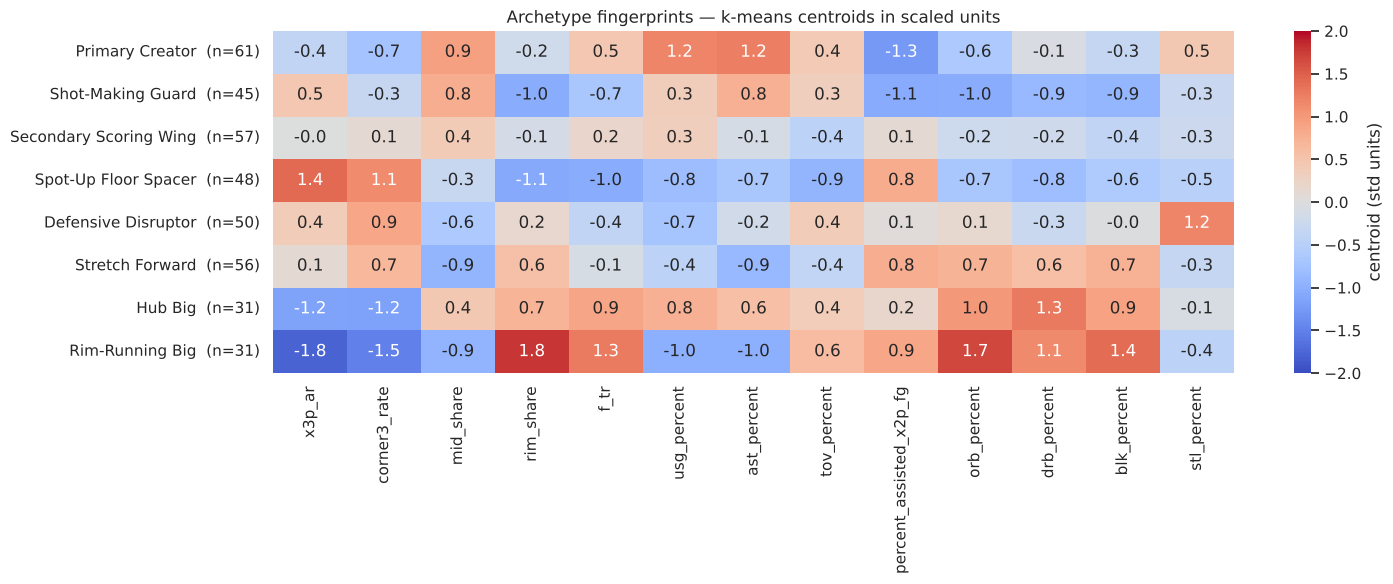

In [5]:
K = 8
km8 = km_models[K]
lab8 = km8.labels_

# Names are attached through an anchor player (a clear, well-known member of each cluster),
# so they stay correct even if cluster numbering changes between library versions.
ANCHORS = {
    'Rudy Gobert':     'Rim-Running Big',
    'Alperen Şengün':  'Hub Big',
    "De'Aaron Fox":    'Primary Creator',
    'Malik Monk':      'Shot-Making Guard',
    'Desmond Bane':    'Secondary Scoring Wing',
    'Luguentz Dort':   'Spot-Up Floor Spacer',
    'Herbert Jones':   'Defensive Disruptor',
    'P.J. Washington': 'Stretch Forward',
}
NAMES = {lab8[power.index[power['player'] == p][0]]: n for p, n in ANCHORS.items()}
assert len(NAMES) == K, 'each anchor player must fall in a different cluster'
ORDER = ['Primary Creator', 'Shot-Making Guard', 'Secondary Scoring Wing', 'Spot-Up Floor Spacer',
         'Defensive Disruptor', 'Stretch Forward', 'Hub Big', 'Rim-Running Big']
archetype = pd.Series([NAMES[l] for l in lab8], name='archetype')

fingerprint = power[FEAT].groupby(archetype).mean().loc[ORDER]
fingerprint.insert(0, 'n', archetype.value_counts().loc[ORDER])
fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(fingerprint[FEAT], annot=True, fmt='.1f', cmap='coolwarm', center=0, vmin=-2, vmax=2,
            cbar_kws={'label': 'centroid (std units)'}, ax=ax)
ax.set_yticklabels([f'{n}  (n={fingerprint.loc[n, "n"]})' for n in ORDER], rotation=0)
ax.set(title='Archetype fingerprints — k-means centroids in scaled units', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

### 4b. Profiles in real units and representative members

**Goal.** Translate the fingerprints into basketball numbers (medians of the *raw* features) and list each archetype's
most typical members, the players closest to the centroid.

**What to look for.** Whether the representative players clearly share a role, and how many different *listed*
positions each archetype draws from.

In [6]:
profile = raw[FEAT].groupby(archetype).median().loc[ORDER]
profile.insert(0, 'players', archetype.value_counts().loc[ORDER])
for p in ['PC1', 'PC2', 'PC3']:
    profile[p] = pcs[p].groupby(archetype).mean().loc[ORDER]
display(profile.round(2))

dist_to_centre = ((X - km8.cluster_centers_[lab8]) ** 2).sum(axis=1)
members = {}
for n in ORDER:
    m = power.loc[archetype == n].assign(d=dist_to_centre[archetype == n]).nsmallest(6, 'd')
    members[n] = {'most typical members': ', '.join(m['player']),
                  'listed positions': ' · '.join(f'{p} {c}' for p, c in
                                                 power.loc[archetype == n, 'pos'].value_counts().items())}
pd.DataFrame(members).T

,players,x3p_ar,corner3_rate,mid_share,rim_share,f_tr,usg_percent,ast_percent,tov_percent,percent_assisted_x2p_fg,orb_percent,drb_percent,blk_percent,stl_percent,PC1,PC2,PC3
archetype,,,,,,,,,,,,,,,,,
Primary Creator,61,0.34,0.05,0.20,0.20,0.29,25.90,25.90,13.50,0.34,2.70,13.20,1.1,1.9,-0.94,2.47,0.27
Shot-Making Guard,45,0.51,0.08,0.19,0.12,0.18,21.10,20.70,13.10,0.39,2.10,10.20,0.7,1.5,-2.38,0.95,0.08
Secondary Scoring Wing,57,0.42,0.11,0.14,0.21,0.26,20.40,12.70,10.90,0.58,3.60,12.70,1.1,1.5,-0.45,0.07,-0.63
Spot-Up Floor Spacer,48,0.70,0.20,0.08,0.12,0.13,15.15,9.55,9.20,0.71,2.80,10.30,1.0,1.3,-1.83,-2.49,-0.54
Defensive Disruptor,50,0.50,0.18,0.06,0.24,0.20,15.30,12.60,13.05,0.56,4.85,12.65,1.5,2.4,-0.07,-1.08,1.52
Stretch Forward,56,0.45,0.16,0.04,0.32,0.23,16.65,8.40,11.00,0.70,6.65,17.70,2.6,1.5,1.40,-1.57,-0.29
Hub Big,31,0.19,0.03,0.15,0.33,0.36,23.40,17.70,13.50,0.58,8.30,23.40,3.0,1.6,2.13,1.86,-0.47
Rim-Running Big,31,0.01,0.00,0.04,0.63,0.40,13.70,8.90,14.00,0.69,13.40,21.20,4.1,1.5,4.40,0.21,-0.10


,most typical members,listed positions
Primary Creator,"De'Aaron Fox, Donovan Mitchell, Jeremiah Fears, Austin Reaves, Jalen Williams, Ajay Mitchell",PG 31 · SF 13 · SG 12 · PF 5
Shot-Making Guard,"Caleb Love, Malik Monk, Tre Mann, Cam Spencer, Tre Johnson, Bones Hyland",PG 23 · SG 19 · SF 2 · C 1
Secondary Scoring Wing,"Desmond Bane, Will Riley, Quentin Grimes, Brice Sensabaugh, Kyle Kuzma, Jaden Ivey",SG 21 · SF 18 · PF 15 · PG 2 · C 1
Spot-Up Floor Spacer,"Luguentz Dort, Ethan Thompson, Tristan Da Silva, Ben Sheppard, Daeqwon Plowden, Vít Krejčí",SG 20 · SF 15 · PF 8 · PG 5
Defensive Disruptor,"Herbert Jones, Dalen Terry, Aaron Wiggins, Rayan Rupert, Jake LaRavia, Jamir Watkins",SG 24 · SF 11 · PF 9 · PG 6
Stretch Forward,"P.J. Washington, Jaylon Tyson, Leonard Miller, Onyeka Okongwu, Taylor Hendricks, Guerschon Yabusele",PF 25 · C 19 · SF 7 · SG 5
Hub Big,"Evan Mobley, Alperen Şengün, Karl-Anthony Towns, Scottie Barnes, Alex Sarr, Amen Thompson",C 19 · PF 9 · SF 2 · PG 1
Rim-Running Big,"Daniel Gafford, Neemias Queta, Moussa Diabaté, Goga Bitadze, Rudy Gobert, Isaiah Jackson",C 28 · PF 3


### Findings: The archetypes

| Archetype | n | Signature (median) | Typical members |
|---|---|---|---|
| **Primary Creator** | 61 | Usage 26%, AST% 26%, only 34% of 2s assisted, mid-range share 0.20 | Fox, D. Mitchell, Fears, Reaves, J. Williams |
| **Shot-Making Guard** | 45 | Usage 21%, AST% 21%, 3PA rate 0.51, mid-range 0.19, very low rebounding | Love, Monk, Mann, Spencer, Hyland |
| **Secondary Scoring Wing** | 57 | Close to league average on almost everything; usage 20%, low TOV% | Bane, Riley, Grimes, Sensabaugh, Kuzma |
| **Spot-Up Floor Spacer** | 48 | 3PA rate 0.70, corner-3 rate 0.20, usage 15%, 71% of 2s assisted, lowest TOV% | Dort, Thompson, Da Silva, Sheppard, Plowden |
| **Defensive Disruptor** | 50 | Highest steal rate (2.4%), high PC3, low usage, 3PA rate 0.50 | Herb Jones, Terry, Wiggins, Rupert, LaRavia |
| **Stretch Forward** | 56 | 3PA rate 0.45 *and* rim share 0.32, DRB% 18, BLK% 2.6, low AST% | P.J. Washington, Tyson, Miller, Okongwu, Hendricks |
| **Hub Big** | 31 | Big-man rebounding (DRB% 23) and rim work *plus* usage 23% and AST% 18% | Mobley, Şengün, Towns, Barnes, Sarr, A. Thompson |
| **Rim-Running Big** | 31 | Almost no threes (3PA rate 0.01), rim share 0.63, ORB% 13, BLK% 4.1 | Gafford, Queta, Diabaté, Bitadze, Gobert, Jackson |

Observations:
- **Only one archetype is essentially a single position.** Rim-Running Bigs are almost all listed centres. Every other
  archetype draws from at least three listed positions, e.g. *Primary Creator* mixes PGs, SFs, SGs and PFs;
  *Stretch Forward* mixes PFs, Cs, SFs and SGs.
- **"Centre" splits into three different jobs:** Rim-Running Big (finisher and protector), Hub Big (the offense runs
  through them: Jokić, Şengün, Giannis and Wembanyama are here), and Stretch Forward (spacing big).
- **"Guard" splits across several roles:** Primary Creator, Shot-Making Guard (scoring off the dribble with less
  playmaking load), and players who are guards by size but Spot-Up Floor Spacers or Defensive Disruptors by role.
- **Secondary Scoring Wing** is the "middle of the distribution" archetype: average on most axes. It is a real role
  (the second or third option on the wing) but, as §5 shows, also the least sharply defined group.

### 4c. The archetypes on the PCA map

**Goal.** Draw every player on the PC1 × PC2 plane from the PCA notebook (interior ↔ perimeter, off-ball ↔ on-ball),
coloured by archetype, with centroids and well-known players labelled.

**What to look for.** Archetypes should occupy distinct *regions* of the map, but with soft borders where they meet,
which is consistent with the low silhouette values. Archetypes that overlap in PC1–PC2 (e.g. Defensive Disruptor and
Stretch Forward) should be separated by PC3, so a second panel shows PC1 × PC3.

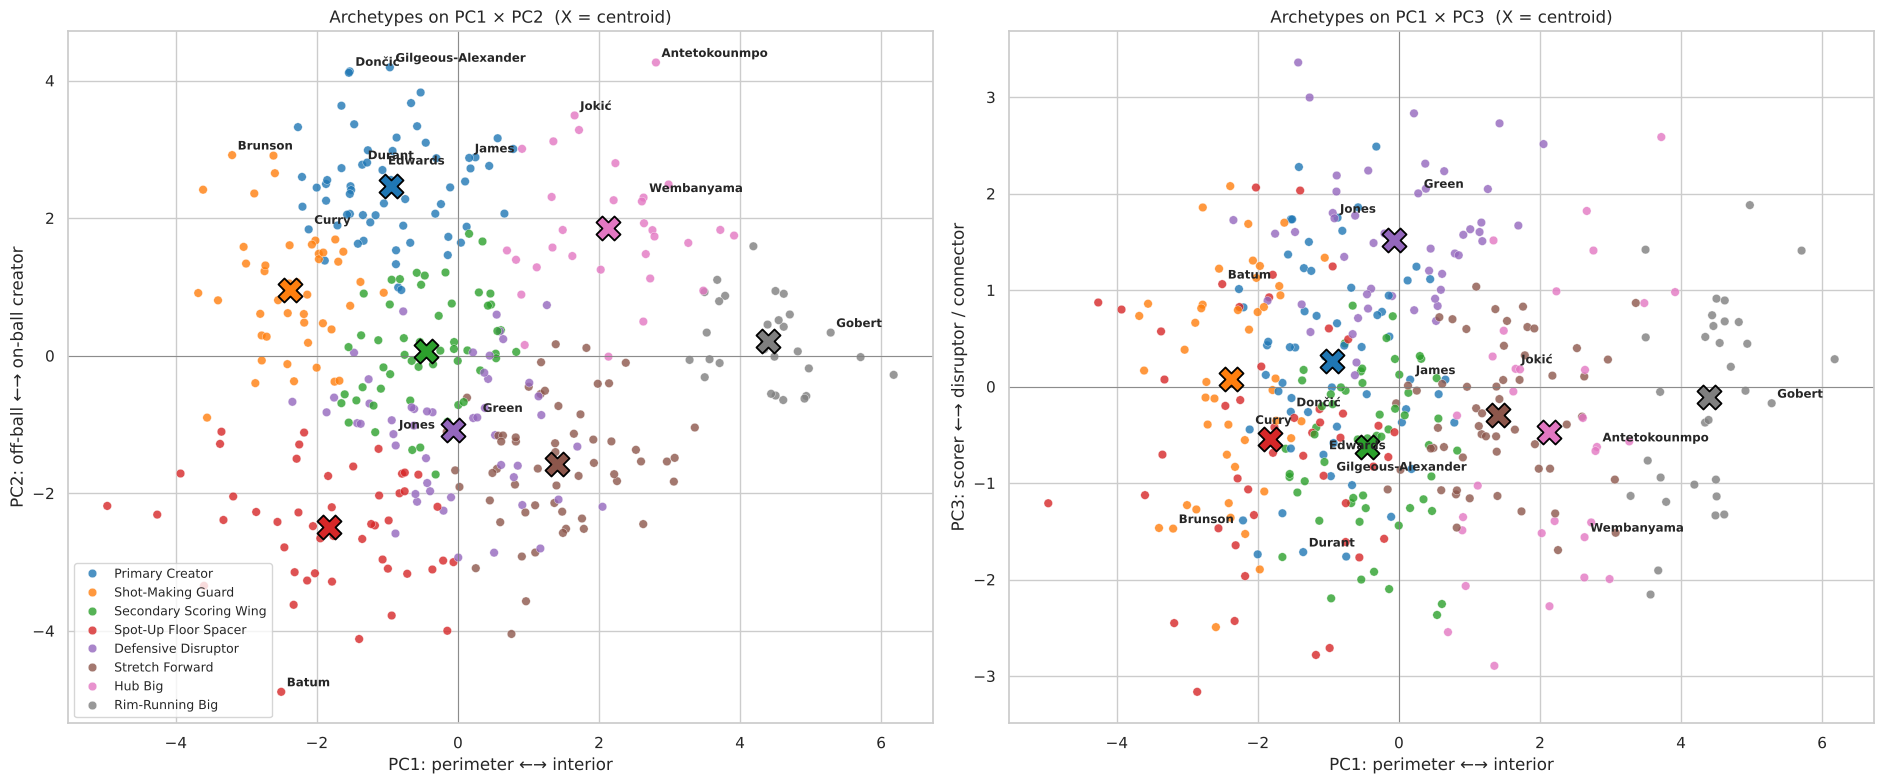

In [7]:
ARCH_PAL = dict(zip(ORDER, sns.color_palette('tab10', K)))
STARS = ['Nikola Jokić', 'Giannis Antetokounmpo', 'Shai Gilgeous-Alexander', 'Luka Dončić', 'Stephen Curry',
         'Rudy Gobert', 'Victor Wembanyama', 'Draymond Green', 'LeBron James', 'Kevin Durant', 'Jalen Brunson',
         'Herbert Jones', 'Nicolas Batum', 'Anthony Edwards']
mp = pd.concat([power[['player', 'pos']], pcs[['PC1', 'PC2', 'PC3']], archetype], axis=1)

fig, ax = plt.subplots(1, 2, figsize=(19, 8))
for a, (xc, yc, xl, yl) in zip(ax, [('PC1', 'PC2', 'PC1: perimeter ←→ interior', 'PC2: off-ball ←→ on-ball creator'),
                                    ('PC1', 'PC3', 'PC1: perimeter ←→ interior', 'PC3: scorer ←→ disruptor / connector')]):
    sns.scatterplot(data=mp, x=xc, y=yc, hue='archetype', hue_order=ORDER, palette=ARCH_PAL, s=38, alpha=0.8,
                    edgecolor='white', linewidth=0.3, ax=a)
    cen = mp.groupby('archetype')[[xc, yc]].mean()
    for n, (x, y) in cen.iterrows():
        a.scatter(x, y, s=300, marker='X', color=ARCH_PAL[n], edgecolor='black', linewidth=1.3, zorder=5)
    for s in STARS:
        r = mp[mp['player'] == s]
        a.annotate(s.split()[-1], (r[xc].iat[0], r[yc].iat[0]), xytext=(4, 4), textcoords='offset points',
                   fontsize=8.5, weight='bold', zorder=6)
    a.axhline(0, color='grey', lw=0.6); a.axvline(0, color='grey', lw=0.6)
    a.set(xlabel=xl, ylabel=yl, title=f'Archetypes on {xc} × {yc}  (X = centroid)')
ax[0].legend(loc='lower left', fontsize=9); ax[1].get_legend().remove()
plt.tight_layout(); plt.show()

**Reading the map.**
- The archetypes tile the PC1 × PC2 plane in an orderly way: creators at the top, spot-up shooters bottom-left,
  rim-runners far right, hub bigs top-right, stretch forwards bottom-right, secondary wings in the middle.
- **Defensive Disruptors sit in the middle of the left panel, overlapping Stretch Forwards and Secondary Scoring
  Wings, but separate clearly upward on PC3** (right panel, centroid at +1.5 vs. −0.3 to −0.6 for those two). This is
  why clustering uses all features and not only the first two components.
- Stars land where their style suggests: Jokić, Giannis and Wembanyama among the Hub Bigs; SGA, Dončić, LeBron, Curry
  and Edwards among the Primary Creators; Draymond Green among the Defensive Disruptors.

---
## 5. How Solid Is Each Archetype?

### 5a. Silhouette plot

**Goal.** Show the silhouette value of *every* player, grouped by archetype.

**How it is computed, for one player.** a = average distance to the other members of the player's own archetype;
b = average distance to the members of the *nearest other* archetype; s = (b − a) / max(a, b).

**How to read the plot.** Each horizontal bar is one player. A long bar to the right means the player clearly belongs to
their archetype; a bar near 0 means the player sits on the border with another archetype; a bar to the *left*
(negative) means the player is, on average, closer to another archetype's members than to their own. The dashed line
is the overall average.

**What to look for.** Archetypes whose bars are mostly long (well-defined) versus mostly short or negative (fuzzy).

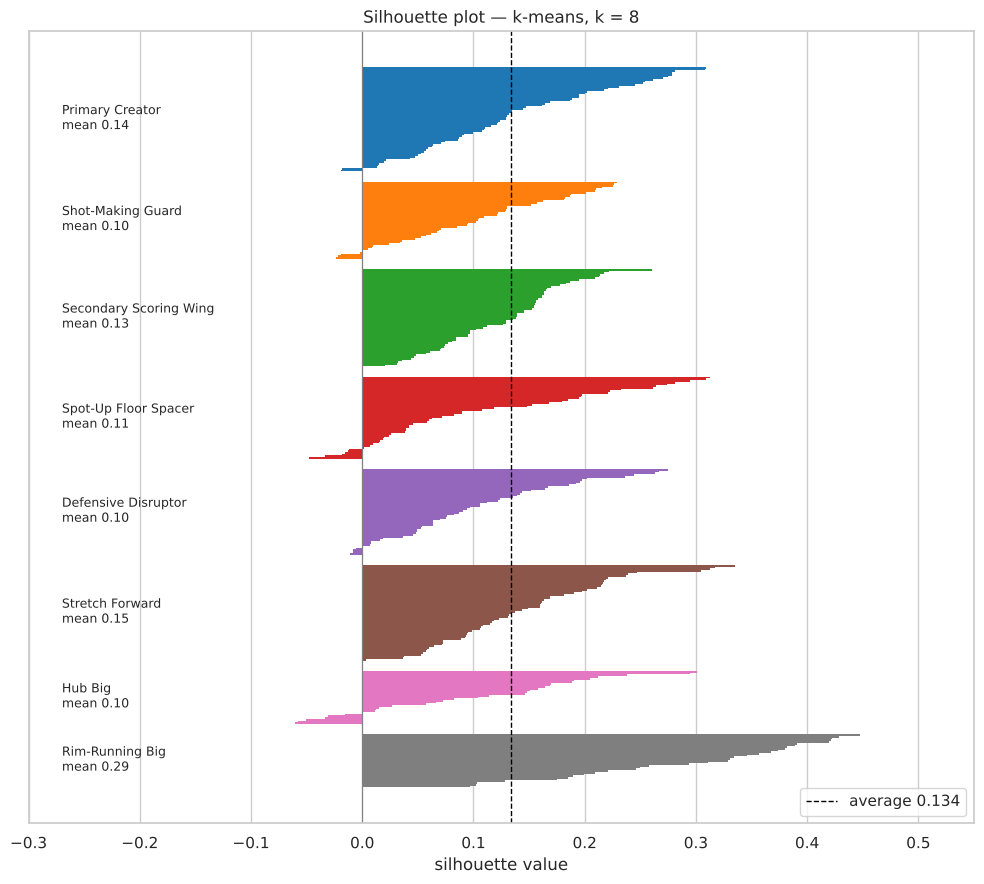

,mean silhouette,% negative
archetype,,
Primary Creator,0.14,3.28
Shot-Making Guard,0.10,11.11
Secondary Scoring Wing,0.13,0.00
Spot-Up Floor Spacer,0.11,12.50
Defensive Disruptor,0.10,10.00
Stretch Forward,0.15,0.00
Hub Big,0.10,19.35
Rim-Running Big,0.29,0.00


In [8]:
sil = silhouette_samples(X, lab8)
fig, ax = plt.subplots(figsize=(10, 9))
y = 0
for n in ORDER[::-1]:
    v = np.sort(sil[archetype == n])
    ax.barh(np.arange(y, y + len(v)), v, height=1.0, color=ARCH_PAL[n], edgecolor='none')
    ax.text(-0.27, y + len(v) / 2, f'{n}\nmean {v.mean():.2f}', va='center', fontsize=9)
    y += len(v) + 6
ax.axvline(sil.mean(), color='black', ls='--', lw=1, label=f'average {sil.mean():.3f}')
ax.axvline(0, color='grey', lw=0.8)
ax.set(xlim=(-0.3, 0.55), yticks=[], xlabel='silhouette value', title='Silhouette plot — k-means, k = 8')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

sil_tab = pd.DataFrame({'mean silhouette': pd.Series(sil).groupby(archetype).mean(),
                        '% negative': pd.Series(sil < 0).groupby(archetype).mean() * 100}).loc[ORDER].round(2)
sil_tab

### 5b. Per-archetype bootstrap stability (Jaccard)

**Goal.** Measure separately for each archetype whether it re-appears when k-means is re-run on resampled data.

**Method.** Draw 100 bootstrap samples of the players, re-run k-means on each, and for every original archetype find
the best-matching resampled cluster. The **Jaccard similarity** (shared members ÷ combined members) of that best match,
averaged over the 100 samples, is the archetype's stability. A common rule of thumb: **> 0.85 highly stable,
0.6–0.85 a valid pattern, 0.5–0.6 indicative of structure, < 0.5 unstable.**

**What to look for.** Which archetypes would survive a different season's data, and which are partly an artefact of
where k-means draws borders in a continuous region.

In [9]:
rng = np.random.default_rng(1)
jac = np.zeros((100, K))
for b in range(100):
    idx = np.unique(rng.choice(len(X), len(X), replace=True))
    lb = KMeans(n_clusters=K, n_init=10, random_state=b).fit(X[idx]).labels_
    for c in range(K):
        a = set(idx[lab8[idx] == c])
        jac[b, c] = max(len(a & set(idx[lb == d])) / len(a | set(idx[lb == d])) for d in range(K))
stab = pd.Series(jac.mean(axis=0), index=[NAMES[c] for c in range(K)]).loc[ORDER]

quality = sil_tab.assign(**{'bootstrap Jaccard': stab.round(2)})
quality['verdict'] = pd.cut(quality['bootstrap Jaccard'], [0, 0.5, 0.6, 0.85, 1],
                            labels=['unstable', 'indicative', 'valid pattern', 'highly stable'])
quality

,mean silhouette,% negative,bootstrap Jaccard,verdict
archetype,,,,
Primary Creator,0.14,3.28,0.61,valid pattern
Shot-Making Guard,0.10,11.11,0.52,indicative
Secondary Scoring Wing,0.13,0.00,0.46,unstable
Spot-Up Floor Spacer,0.11,12.50,0.69,valid pattern
Defensive Disruptor,0.10,10.00,0.53,indicative
Stretch Forward,0.15,0.00,0.64,valid pattern
Hub Big,0.10,19.35,0.58,indicative
Rim-Running Big,0.29,0.00,0.86,highly stable


### Findings: Archetype quality
- **Rim-Running Big is the only highly stable archetype** (Jaccard ≈ 0.86, highest mean silhouette ≈ 0.29): a truly
  distinct role at the edge of the feature space. DBSCAN (§8) independently finds it as a separate dense region.
- **Spot-Up Floor Spacer, Stretch Forward and Primary Creator are valid patterns** (≈ 0.6–0.7).
- **Hub Big, Defensive Disruptor and Shot-Making Guard are indicative** (≈ 0.5–0.6): the role is real, but its border
  with neighbouring archetypes moves between samples. **Hub Big has the most negative silhouettes (19%)**: it is a
  small, spread-out group (Giannis, Jokić and Bam Adebayo are far apart from one another), and several of its members
  are individually closer to the Stretch Forwards or Primary Creators.
- **Secondary Scoring Wing is unstable** (≈ 0.46) even though none of its players has a negative silhouette. The two
  measures answer different questions. Silhouette says its members are, on average, closer to each other than to any
  other single group. Bootstrap stability says the group's *borders* move from sample to sample. It sits in the
  *middle* of the continuum, average on most axes and surrounded by other archetypes on every side. It is kept as a
  label, but should be read as "versatile / no dominant specialty" rather than as a sharply defined archetype.

---
## 6. Border Players: Who Sits Between Two Archetypes?

**Goal.** Use each player's silhouette to flag **border players**, whose role straddles two archetypes, and identify
the *second* archetype they lean toward.

**Why it matters.** k-means gives every player exactly one label, even a player who is almost equally close to two
centroids. On a continuum, those in-between players are as informative as the archetypes themselves: they are the
genuinely versatile players. The silhouette makes this measurable without changing the model:
- **s close to 0** → the player is about as close to the nearest *other* archetype as to their own;
- **s < 0** → the player is closer to the other archetype.

We flag a player as a **border player** when **s < 0.05**. The archetype that defines *b* in the silhouette formula,
the nearest other archetype by average distance, is reported as the player's **second archetype**.

**What to look for.** How many players are border players, which archetype pairs they fall between, and whether the
well-known "versatile" players appear.

border players (silhouette < 0.05): 78 of 379 (21%); of which negative: 24


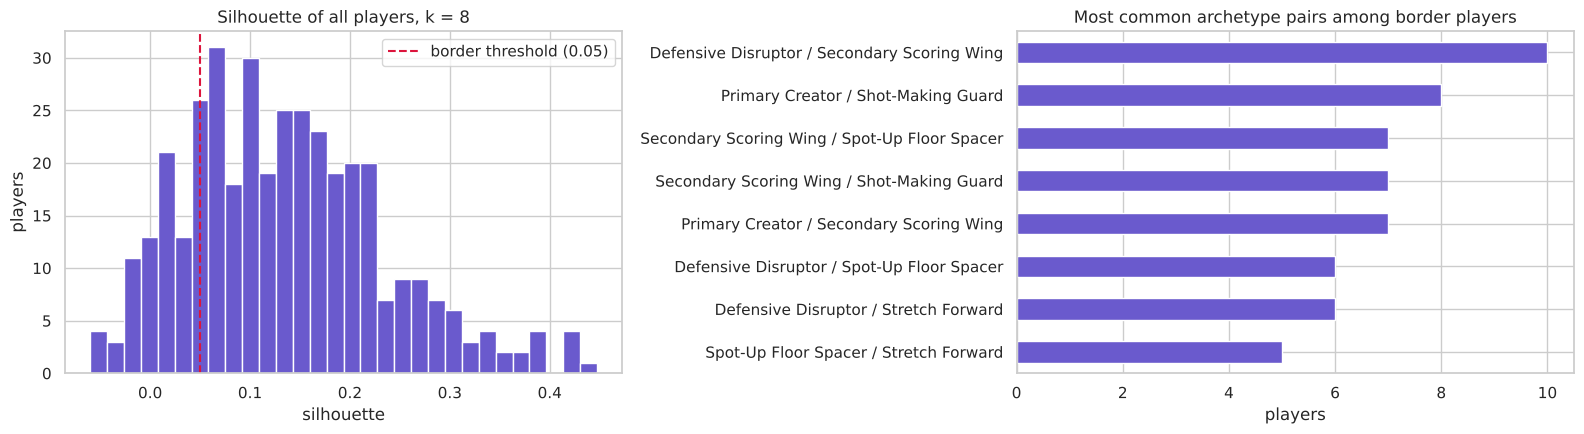

In [10]:
D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))      # player-to-player distances
mean_to = pd.DataFrame({NAMES[c]: D[:, lab8 == c].mean(axis=1) for c in range(K)})
for i, n in enumerate(archetype):                                       # exclude own archetype -> nearest other
    mean_to.loc[i, n] = np.inf
second = mean_to.idxmin(axis=1)
border = sil < 0.05

print(f'border players (silhouette < 0.05): {border.sum()} of {len(X)} ({border.mean():.0%}); '
      f'of which negative: {(sil < 0).sum()}')
pairs = pd.Series([' / '.join(sorted([a, b])) for a, b in zip(archetype[border], second[border])]).value_counts()

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].hist(sil, bins=30, color='slateblue', edgecolor='white')
ax[0].axvline(0.05, color='crimson', ls='--', label='border threshold (0.05)')
ax[0].set(title='Silhouette of all players, k = 8', xlabel='silhouette', ylabel='players'); ax[0].legend()
pairs.head(8).sort_values().plot.barh(ax=ax[1], color='slateblue')
ax[1].set(title='Most common archetype pairs among border players', xlabel='players')
plt.tight_layout(); plt.show()

**Goal.** Show the archetype and silhouette of well-known players, and list the clearest border players.

**What to look for.** Stars whose silhouette is near zero (their game combines two roles), and whether the border list
matches basketball intuition about versatile players.

In [11]:
star_idx = [power.index[power['player'] == s][0] for s in STARS]
display(pd.DataFrame({'player': power.loc[star_idx, 'player'].values, 'listed': power.loc[star_idx, 'pos'].values,
                      'archetype': archetype[star_idx].values, 'silhouette': sil[star_idx].round(2),
                      'second archetype': second[star_idx].values}))
bp = pd.DataFrame({'player': power['player'], 'pos': power['pos'], 'archetype': archetype,
                   'second archetype': second, 'silhouette': sil.round(3)})[border]
print('Clearest border players (lowest silhouette):')
bp.nsmallest(12, 'silhouette')

,player,listed,archetype,silhouette,second archetype
0,Nikola Jokić,C,Hub Big,0.15,Primary Creator
1,Giannis Antetokounmpo,PF,Hub Big,0.21,Primary Creator
2,Shai Gilgeous-Alexander,PG,Primary Creator,0.28,Shot-Making Guard
3,Luka Dončić,PG,Primary Creator,0.25,Shot-Making Guard
4,Stephen Curry,PG,Primary Creator,0.05,Shot-Making Guard
5,Rudy Gobert,C,Rim-Running Big,0.45,Hub Big
6,Victor Wembanyama,C,Hub Big,0.30,Rim-Running Big
7,Draymond Green,PF,Defensive Disruptor,0.06,Stretch Forward
8,LeBron James,SF,Primary Creator,0.19,Hub Big
9,Kevin Durant,SF,Primary Creator,0.09,Shot-Making Guard


Clearest border players (lowest silhouette):


,player,pos,archetype,second archetype,silhouette
2,Bam Adebayo,C,Hub Big,Secondary Scoring Wing,-0.060
193,Jonathan Kuminga,PF,Hub Big,Secondary Scoring Wing,-0.058
139,Isaiah Hartenstein,C,Hub Big,Rim-Running Big,-0.051
242,Pete Nance,PF,Spot-Up Floor Spacer,Stretch Forward,-0.048
172,Cameron Johnson,SF,Spot-Up Floor Spacer,Secondary Scoring Wing,-0.034
62,Nic Claxton,C,Hub Big,Rim-Running Big,-0.033
341,Nikola Vučević,C,Hub Big,Secondary Scoring Wing,-0.031
45,Kentavious Caldwell-Pope,SG,Shot-Making Guard,Secondary Scoring Wing,-0.024
198,Zach LaVine,SG,Shot-Making Guard,Secondary Scoring Wing,-0.022
32,Jamaree Bouyea,PG,Primary Creator,Secondary Scoring Wing,-0.019


### Findings: Border players
- **78 players (21%) are border players**, and 24 of them have a negative silhouette (they are closer, on average, to
  another archetype). This is the direct consequence of the low average silhouette.
- **Secondary Scoring Wing is by far the most common second archetype** (32 of the 78), consistent with its central,
  unstable position (§5). The most frequent pairs are Defensive Disruptor / Secondary Scoring Wing (10), Primary
  Creator / Shot-Making Guard (8), and Secondary Scoring Wing with Shot-Making Guard, Primary Creator or Spot-Up Floor
  Spacer (7 each). No border player leans from one edge of the map to the other: there is no Rim-Running Big leaning
  toward Spot-Up Floor Spacer, for example. This mirrors the play-by-play finding from the EDA, where listed and played
  positions disagreed only between neighbouring slots.
- **The clearest border players are Hub Bigs**: Bam Adebayo, Jonathan Kuminga and Nikola Vučević lean toward Secondary
  Scoring Wing, Isaiah Hartenstein and Nic Claxton toward Rim-Running Big. This is the "spread-out" Hub Big group seen in
  §5.
- **Several stars sit on or near a border:** Jalen Brunson (0.01, Shot-Making Guard ↔ Primary Creator), Stephen Curry
  (0.05, Primary Creator ↔ Shot-Making Guard), Draymond Green (0.06, Defensive Disruptor ↔ Stretch Forward) and Kevin
  Durant (0.09, Primary Creator ↔ Shot-Making Guard). Their second archetype describes the other half of their game.
  By contrast Gobert (0.45), Wembanyama (0.30) and SGA (0.28) are clear members of their archetype.
- The border flag and second archetype are exported, so later notebooks can treat these players separately (for
  instance, as candidates for "unique profile" in the anomaly analysis).

---
## 7. Are the k-means Results Robust to Preprocessing Choices?

**Goal.** Re-run k-means on alternative versions of the input and compare the labels with the primary solution, at
both levels of the taxonomy.

**Measure: Adjusted Rand Index (ARI).** ARI compares two partitions of the same players, ignoring label names: 1 =
identical groupings, 0 = no more agreement than random labelling. It is the same measure the validation notebook will
use against listed positions.

| Alternative input | Question |
|---|---|
| StandardScaler instead of PowerTransformer | Does the scaling choice from notebook 02 drive the result? |
| 3 PC scores instead of 13 features | Do the archetypes survive on the dominant structure alone? |
| 5 PC scores | Does adding the unstable PC4–PC5 change anything? |

**What to look for.** High agreement at k = 3 means the families are robust; agreement at k = 8 shows how much of the
finer structure depends on the input.

In [12]:
def km(data, k):
    return KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(data)

alts = {'StandardScaler features (13)': standard[FEAT].values,
        '3 PC scores': pcs[['PC1', 'PC2', 'PC3']].values,
        '5 PC scores': pcs[['PC1', 'PC2', 'PC3', 'PC4', 'PC5']].values}
agree = pd.DataFrame({f'ARI at k = {k}': {name: adjusted_rand_score(km_models[k].labels_, km(d, k))
                                          for name, d in alts.items()} for k in (3, 8)})
agree.round(2)

,ARI at k = 3,ARI at k = 8
StandardScaler features (13),0.82,0.62
3 PC scores,0.96,0.68
5 PC scores,0.90,0.70


### Findings: Robustness
- **The 3 families are robust to every preprocessing choice** (ARI 0.82 with StandardScaler, 0.90–0.96 with PC scores).
- **The 8 archetypes agree moderately** (ARI ≈ 0.6–0.7). They are recognisably the same across inputs, but border
  players move, fully consistent with the per-archetype stability (§5) and the border-player analysis (§6).
- Practical reading: **the family label is a robust fact about the data; the archetype label is a useful,
  interpretable description whose borders are soft.** Both are exported, along with each player's silhouette.

---
## 8. DBSCAN: A Density-Based Perspective

k-means assumes every player belongs to some centre. **DBSCAN** asks a different question: *where are the crowded
regions of the style space, and which players live outside them?*

**How DBSCAN works.** Two parameters:
- **ε (eps)**: the neighbourhood radius;
- **`min_samples`**: how many players (including the player itself) must lie within ε for a neighbourhood to count
  as dense.

Every player is then one of three types:

| Type | Rule |
|---|---|
| **Core** | at least `min_samples` players within ε |
| **Border** | not core, but within ε of a core point |
| **Noise** | neither, so not assigned to any cluster |

A cluster is a set of core points that are chained together through overlapping neighbourhoods, plus their border
points. There is no *k*: the number of clusters is an *output*.

**Why it is useful here.** If the archetypes were separated by empty space, DBSCAN would find them as separate dense
regions. If roles form a continuum, DBSCAN will instead see one large connected body, and the players it marks as
**noise** are those with an unusual combination of features, which leads directly into the anomaly analysis.

### 8a. Choosing a sensible range for ε: the k-distance plot

**Goal.** For each player, compute the distance to their `min_samples`-th nearest neighbour and sort these distances.

**How to read it.** Dense regions produce small k-distances; the sorted curve rises slowly and then bends sharply
upward for the few players in sparse regions. The bend (the "knee") is the usual starting point for ε: a smaller ε
leaves most players as noise, a much larger one merges everything.

**What to look for.** Where the curves bend, and how that range depends on `min_samples`.

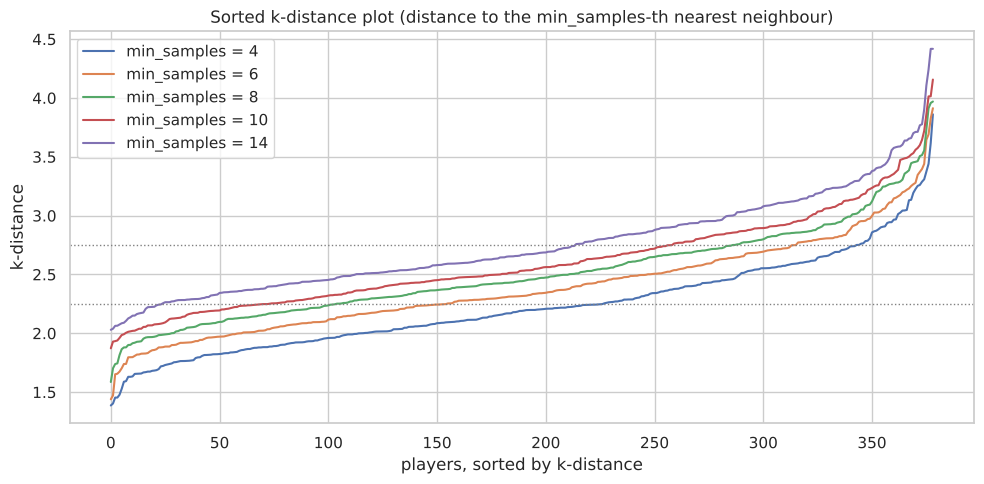

In [13]:
MS_VALUES = [4, 6, 8, 10, 14]
fig, ax = plt.subplots(figsize=(10, 5))
for ms in MS_VALUES:
    kd = np.sort(NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)[0][:, -1])
    ax.plot(kd, label=f'min_samples = {ms}')
for e in (2.25, 2.75):
    ax.axhline(e, color='grey', ls=':', lw=1)
ax.set(title='Sorted k-distance plot (distance to the min_samples-th nearest neighbour)',
       xlabel='players, sorted by k-distance', ylabel='k-distance'); ax.legend()
plt.tight_layout(); plt.show()

**Reading the plot.** The curves rise smoothly (for `min_samples` = 6, from about 1.5 to 3.1 across 95% of the
players) and bend sharply upward only for the last few percent of players. There are no plateaus or steps in between, which
would indicate separate dense groups. A smooth curve like this is itself evidence of continuous density, with no gaps
between groups. The interesting range for ε is therefore roughly **2.0–3.0**: below it most players are noise, above it
everything merges. The two dotted lines mark the two settings examined below (2.25 and 2.75).

### 8b. Parameter sweep over ε and `min_samples`

**Goal.** Run DBSCAN on a grid of ε (1.5 → 4.0) and `min_samples` (4 → 14) and record the number of clusters, the share
of noise, and the size of the largest cluster.

**What to look for.** Whether *any* setting produces several sizeable clusters (as k-means does), or whether DBSCAN
always ends up with one large body plus noise.

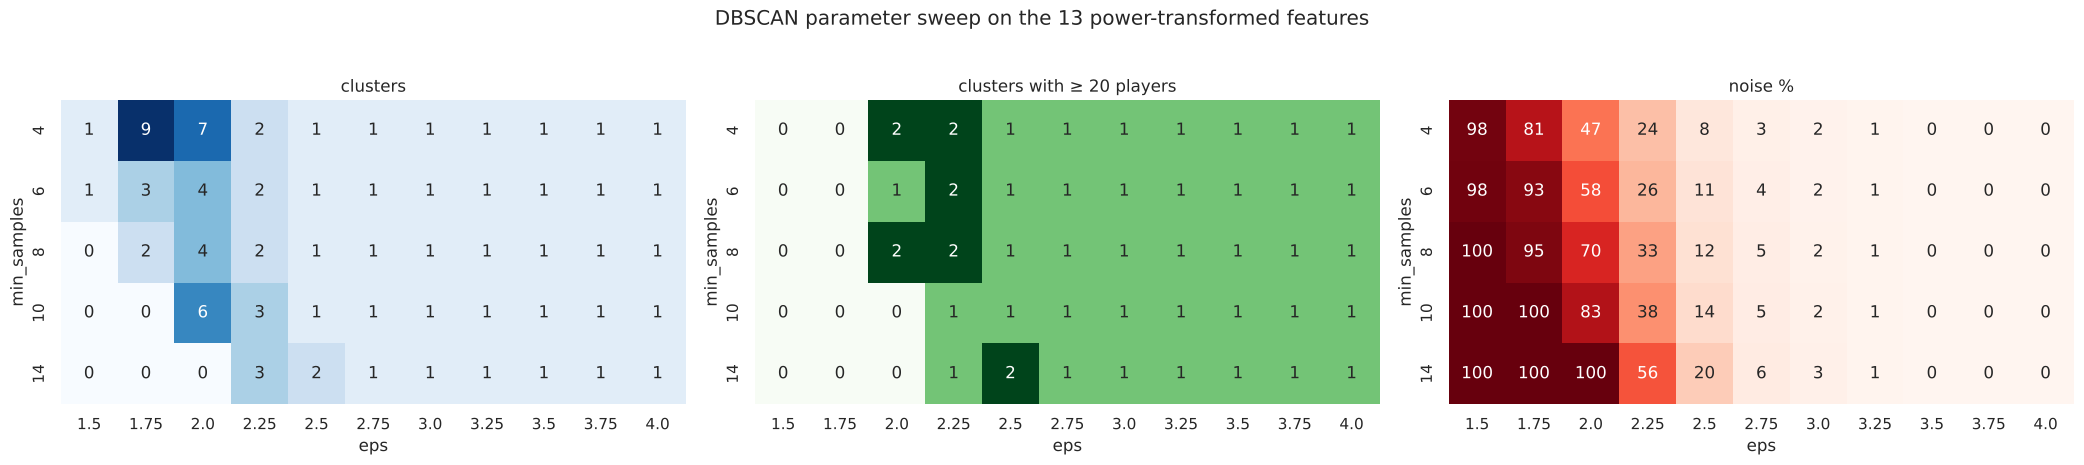

In [14]:
EPS_VALUES = np.round(np.arange(1.5, 4.01, 0.25), 2)
sweep = []
for ms in MS_VALUES:
    for eps in EPS_VALUES:
        l = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        sizes = np.bincount(l[l >= 0]) if (l >= 0).any() else np.array([0])
        sweep.append({'min_samples': ms, 'eps': eps, 'clusters': len(set(l) - {-1}),
                      'noise %': (l == -1).mean() * 100, 'largest cluster': sizes.max(),
                      'clusters with ≥ 20 players': int((sizes >= 20).sum())})
sweep = pd.DataFrame(sweep)

fig, ax = plt.subplots(1, 3, figsize=(21, 4.5))
for a, col, fmt, cmap in [(ax[0], 'clusters', 'd', 'Blues'), (ax[1], 'clusters with ≥ 20 players', 'd', 'Greens'),
                          (ax[2], 'noise %', '.0f', 'Reds')]:
    sns.heatmap(sweep.pivot(index='min_samples', columns='eps', values=col), annot=True, fmt=fmt, cmap=cmap,
                cbar=False, ax=a)
    a.set(title=col)
plt.suptitle('DBSCAN parameter sweep on the 13 power-transformed features', y=1.03)
plt.tight_layout(); plt.show()

**Goal.** Check a property of DBSCAN directly on this data: increasing ε only ever *adds* neighbours, so it can only
turn noise into cluster members and merge clusters, never split a cluster.

**What to look for.** The noise share should fall monotonically as ε grows, for every `min_samples`.

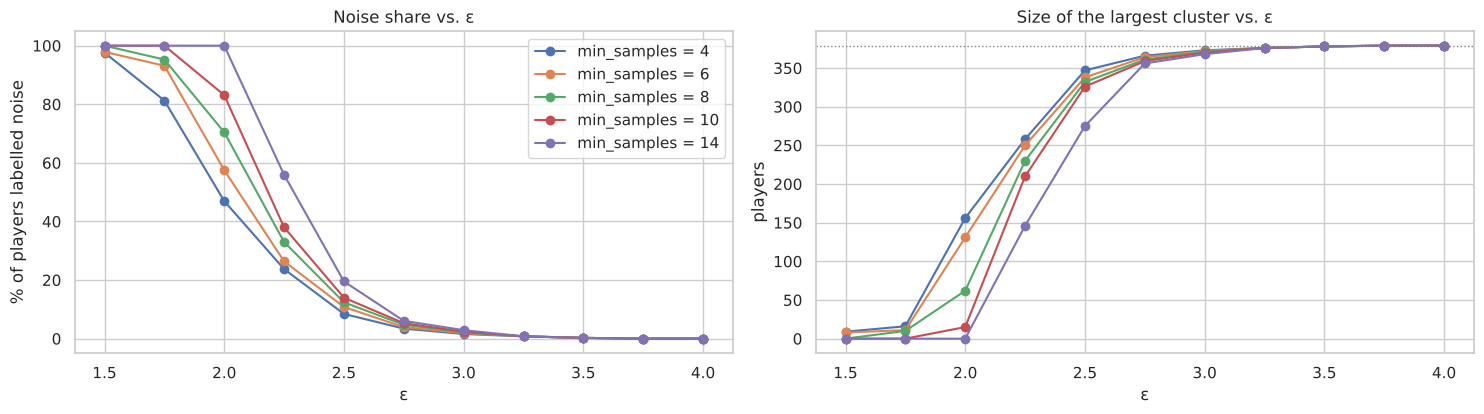

noise share never increases with ε: True


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
for ms in MS_VALUES:
    s = sweep[sweep['min_samples'] == ms]
    ax[0].plot(s['eps'], s['noise %'], 'o-', label=f'min_samples = {ms}')
    ax[1].plot(s['eps'], s['largest cluster'], 'o-', label=f'min_samples = {ms}')
ax[0].set(title='Noise share vs. ε', xlabel='ε', ylabel='% of players labelled noise')
ax[1].set(title='Size of the largest cluster vs. ε', xlabel='ε', ylabel='players')
ax[1].axhline(len(X), color='grey', ls=':', lw=1); ax[0].legend(); plt.tight_layout(); plt.show()
print('noise share never increases with ε:',
      all((np.diff(sweep[sweep['min_samples'] == ms]['noise %']) <= 1e-9).all() for ms in MS_VALUES))

### Findings: Parameter sweep
- **DBSCAN never reproduces the k-means archetypes: in the entire grid there are never more than two clusters with
  20 or more players.** At small ε (≤ 1.75) 81–100% of players are noise and any clusters are tiny. As soon as ε is
  large enough to connect the main population (2.5, or 2.75 for `min_samples` = 14), **everything merges into one
  cluster**, and only a shrinking fringe of noise remains.
- **Two sizeable clusters appear only in a narrow band**: ε = 2.0–2.25 for `min_samples` 4–8, ε = 2.5 for
  `min_samples` = 14. ε = 2.25 with `min_samples` = 6 sits in the middle of that band and is examined in §8c.
- As expected, noise falls monotonically with ε and the largest cluster only grows: clusters merge and absorb noise,
  but never split.
- This is the strongest evidence so far that **there are no empty gaps between most archetypes**. The players form one
  continuous, connected cloud. The k-means archetypes are a *partition* of that cloud, not naturally separated islands.

### 8c. The structure setting: ε = 2.25, `min_samples` = 6

**Goal.** Examine the setting that yields more than one sizeable dense region, and compare DBSCAN's groups with the
k-means archetypes.

**What to look for.** Which players form the dense regions, and which archetypes contribute most of the noise points.

In [16]:
EPS_S, MS_S = 2.25, 6
db = DBSCAN(eps=EPS_S, min_samples=MS_S).fit(X)
db_lab = db.labels_
ptype = np.full(len(X), 'noise', dtype=object)
ptype[db_lab >= 0] = 'border'
ptype[db.core_sample_indices_] = 'core'

# name DBSCAN clusters by their position on PC1 (interior vs. perimeter)
pc1_mean = pd.Series(pcs['PC1'].values).groupby(db_lab).mean().drop(-1, errors='ignore')
DB_NAMES = {c: ('Dense interior core' if pc1_mean[c] == pc1_mean.max() else 'Dense perimeter core')
            for c in pc1_mean.index}
DB_NAMES[-1] = 'Noise'
db_group = pd.Series([DB_NAMES[l] for l in db_lab], name='dbscan_group')

print(f'ε = {EPS_S}, min_samples = {MS_S}:', db_group.value_counts().to_dict())
print('point types:', pd.Series(ptype).value_counts().to_dict())
ct_db = pd.crosstab(archetype, db_group).loc[ORDER]
ct_db['% noise'] = (ct_db['Noise'] / ct_db.sum(axis=1) * 100).round(0)
ct_db

ε = 2.25, min_samples = 6: {'Dense perimeter core': 250, 'Noise': 100, 'Dense interior core': 29}
point types: {'core': 155, 'border': 124, 'noise': 100}


dbscan_group,Dense interior core,Dense perimeter core,Noise,% noise
archetype,,,,
Primary Creator,0,52,9,15.0
Shot-Making Guard,0,33,12,27.0
Secondary Scoring Wing,0,48,9,16.0
Spot-Up Floor Spacer,0,25,23,48.0
Defensive Disruptor,0,39,11,22.0
Stretch Forward,1,46,9,16.0
Hub Big,6,7,18,58.0
Rim-Running Big,22,0,9,29.0


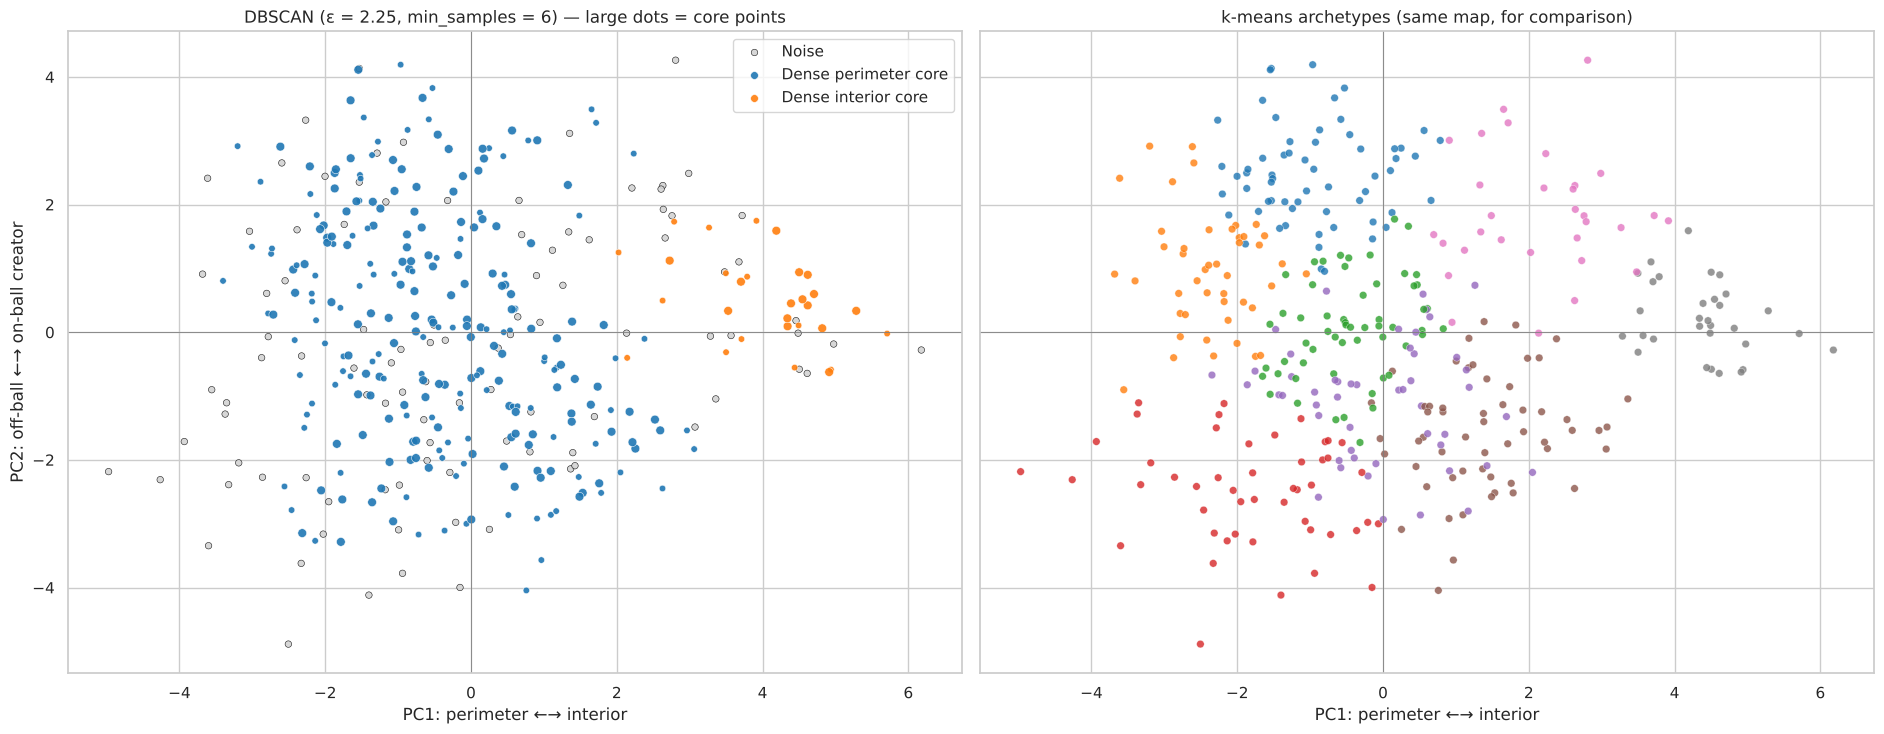

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(19, 7.5), sharex=True, sharey=True)
DB_PAL = {'Dense perimeter core': 'tab:blue', 'Dense interior core': 'tab:orange', 'Noise': 'lightgrey'}
dm = pd.concat([mp, db_group, pd.Series(ptype, name='point type')], axis=1)
for g in ['Noise', 'Dense perimeter core', 'Dense interior core']:
    d = dm[dm['dbscan_group'] == g]
    ax[0].scatter(d['PC1'], d['PC2'], s=np.where(d['point type'] == 'core', 40, 22), color=DB_PAL[g],
                  edgecolor='black' if g == 'Noise' else 'white', linewidth=0.4, label=g, alpha=0.9)
ax[0].set(title=f'DBSCAN (ε = {EPS_S}, min_samples = {MS_S}) — large dots = core points',
          xlabel='PC1: perimeter ←→ interior', ylabel='PC2: off-ball ←→ on-ball creator'); ax[0].legend()
sns.scatterplot(data=mp, x='PC1', y='PC2', hue='archetype', hue_order=ORDER, palette=ARCH_PAL, s=30, alpha=0.8,
                edgecolor='white', linewidth=0.3, ax=ax[1], legend=False)
ax[1].set(title='k-means archetypes (same map, for comparison)', xlabel='PC1: perimeter ←→ interior', ylabel='')
for a in ax:
    a.axhline(0, color='grey', lw=0.6); a.axvline(0, color='grey', lw=0.6)
plt.tight_layout(); plt.show()

### Findings: Dense cores vs. noise
- At this setting DBSCAN finds exactly **two dense regions**:
  - a small **dense interior core**, made up mostly of **Rim-Running Bigs** plus a few Hub Bigs, the same
    archetype that k-means found to be the most stable (Jaccard ≈ 0.86);
  - one large **dense perimeter core** containing the creators, shooters, wings and stretch forwards all together.
    DBSCAN sees no low-density gap between them.
- **About a quarter of players (100) are noise** at this setting, but very unevenly: **58% of Hub Bigs and 48% of
  Spot-Up Floor Spacers** are noise, against only 15–16% of Primary Creators, Secondary Scoring Wings and Stretch
  Forwards. Hub Bigs are few and spread out; Spot-Up Floor Spacers sit at the far perimeter edge of the map. Noise
  here means "lives in a sparse part of the style space", not "weak player".
- **The two methods are complementary.** k-means partitions the continuum into interpretable roles; DBSCAN shows that
  only the rim-running big is separated from the rest by genuinely lower density.

### 8d. The outlier setting: who remains noise at a larger ε?

**Goal.** Increase ε to 2.75 (just past the knee of the k-distance curve) so that nearly the whole league is connected,
and list the players that are **still** noise.

**Why it matters.** At this radius a player has to be genuinely far from any dense neighbourhood to stay unassigned.
These players are DBSCAN's candidates for **one-of-a-kind statistical profiles**, the starting point for the
anomaly-detection notebook.

In [18]:
EPS_O = 2.75
db_out = DBSCAN(eps=EPS_O, min_samples=MS_S).fit_predict(X)
noise_strict = db_out == -1
print(f'ε = {EPS_O}, min_samples = {MS_S}: {len(set(db_out) - {-1})} cluster(s), '
      f'{noise_strict.sum()} noise players ({noise_strict.mean():.0%})')
pd.DataFrame({'player': power['player'], 'pos': power['pos'], 'archetype': archetype,
              'silhouette': sil.round(2), 'border player': border})[noise_strict].sort_values('archetype')

ε = 2.75, min_samples = 6: 1 cluster(s), 15 noise players (4%)


,player,pos,archetype,silhouette,border player
18,Lonzo Ball,PG,Defensive Disruptor,0.17,False
125,Draymond Green,PF,Defensive Disruptor,0.06,False
254,Gary Payton II,SG,Defensive Disruptor,0.01,True
306,Day'Ron Sharpe,C,Hub Big,-0.02,True
79,DeMar DeRozan,PF,Primary Creator,0.06,False
218,T.J. McConnell,PG,Primary Creator,0.07,False
270,Dwight Powell,C,Rim-Running Big,0.29,False
285,Nick Richards,C,Rim-Running Big,0.25,False
313,Jericho Sims,C,Rim-Running Big,0.26,False
26,Nicolas Batum,PF,Spot-Up Floor Spacer,0.18,False


### Findings: DBSCAN outliers
- At ε = 2.75 the league is a **single cluster**, and only about 4% of players remain noise.
- The list is basketball-meaningful. These are players whose *combination* of features is rare:
  - **Draymond Green**: lead-guard playmaking (AST% 27) with big-man defensive rebounding (DRB% 19.5) on modest usage
    (16%), while taking 63% of shots from three.
  - **Nicolas Batum**: 96% of shots are threes, 42% of *all* shots are corner threes, at a usage of only 9.6%.
  - **T.J. McConnell**: the league's second-highest assist rate (50%) combined with a mid-range-heavy shot diet (47%)
    and almost no threes.
  - **Lonzo Ball**: 84% of shots are threes, yet assists like a creator (AST% 23) on 14% usage, with a top-12 steal rate.
  - **DeMar DeRozan**: the most mid-range-heavy shot diet in the league (58% of shots).
- **Only 3 of the 15 are border players.** Most have clearly positive silhouettes (e.g. Sims, Powell, Hauser ≈ 0.26–0.29):
  they are **extreme versions of their own archetype** rather than players caught between two. Being *unusual* and being
  *in-between* are different things, a distinction notebook 05 investigates with several ways of measuring "unusual".

---
## 9. Archetypes vs. Listed Positions, and Export

**Goal.** Cross-tabulate the archetypes against listed positions, and the archetypes against the 3 families, as a
preview of the formal validation (ARI against listed and played positions) in the final notebook.

**What to look for.** Rows (archetypes) spread across many columns (positions) are roles that the position system
cannot express; columns spread across many rows are positions that hide several roles.

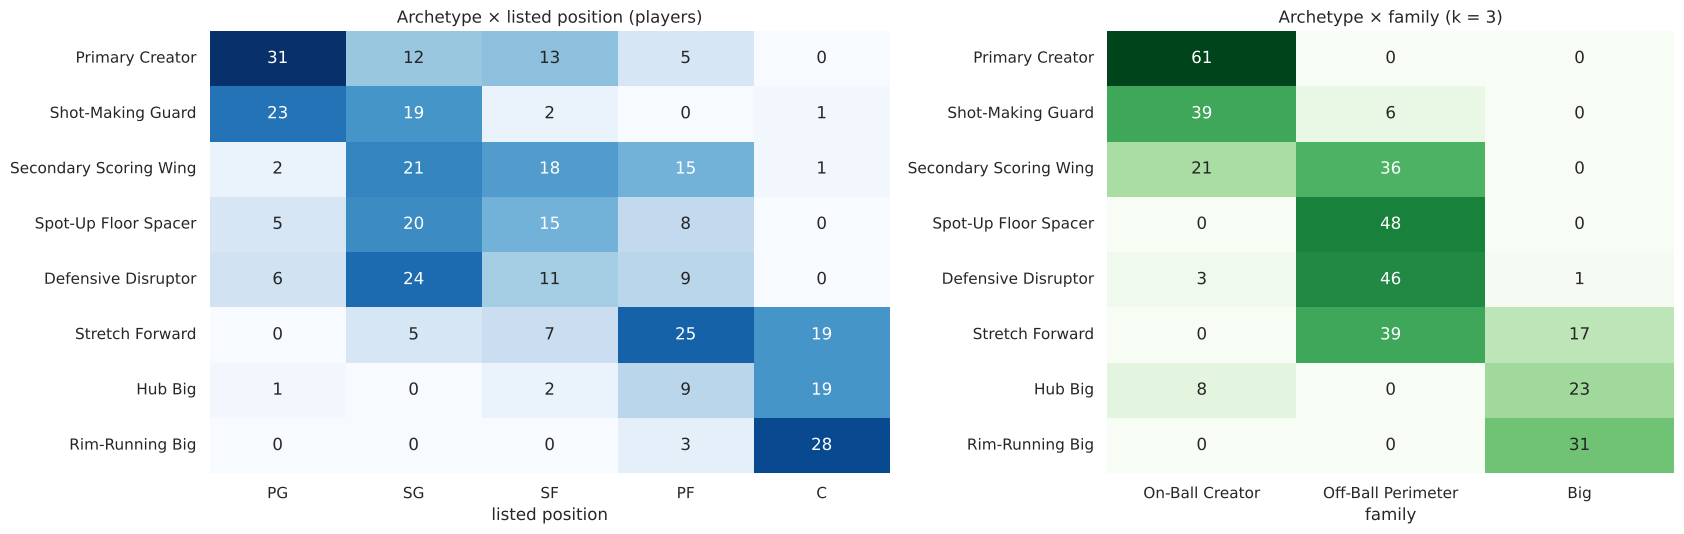

ARI archetypes vs. listed position: 0.14 | families vs. listed position: 0.17


In [19]:
FAM_ANCHORS = {'Rudy Gobert': 'Big', "De'Aaron Fox": 'On-Ball Creator', 'Luguentz Dort': 'Off-Ball Perimeter'}
fam_lab = km_models[3].labels_
FAM = {fam_lab[power.index[power['player'] == p][0]]: n for p, n in FAM_ANCHORS.items()}
assert len(FAM) == 3
family = pd.Series([FAM[l] for l in fam_lab], name='family')

ct = pd.crosstab(archetype, power['pos']).loc[ORDER, POS_ORDER]
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [1.2, 1]})
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])
ax[0].set(title='Archetype × listed position (players)', xlabel='listed position', ylabel='')
fa = pd.crosstab(archetype, family).loc[ORDER, ['On-Ball Creator', 'Off-Ball Perimeter', 'Big']]
sns.heatmap(fa, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax[1])
ax[1].set(title='Archetype × family (k = 3)', xlabel='family', ylabel='')
plt.tight_layout(); plt.show()
print(f'ARI archetypes vs. listed position: {adjusted_rand_score(archetype, power["pos"]):.2f} | '
      f'families vs. listed position: {adjusted_rand_score(family, power["pos"]):.2f}')

### Findings: Archetypes vs. positions
- **Most archetypes span three or more listed positions**, and every listed position except C feeds at least four
  archetypes (counting only cells with 3 or more players). The archetype system and the position system are measuring
  different things.
- **ARI between archetypes and listed positions is low**: the clusters are not a re-labelling of positions. Formal
  validation (including against play-by-play positions) follows in the final notebook.
- **Archetypes nest *approximately* inside families**: Primary Creators and Shot-Making Guards are On-Ball Creators;
  Rim-Running Bigs are Bigs; Spot-Up Floor Spacers and Defensive Disruptors are Off-Ball Perimeter. Stretch Forwards and
  Hub Bigs are split between two families, and Secondary Scoring Wings between creators and off-ball players, which is
  exactly where the continuum is.

### Export

**Goal.** Save one row per player with both levels of k-means labels, quality indicators and the DBSCAN assignments,
ready for the anomaly-detection and validation notebooks.

| Column | Meaning |
|---|---|
| `family` | k-means k = 3 label (robust) |
| `archetype` | k-means k = 8 label |
| `silhouette`, `second_archetype`, `border_player` | fit to the archetype; nearest other archetype; silhouette < 0.05 |
| `dbscan_group`, `dbscan_point_type` | DBSCAN at ε = 2.25, min_samples = 6: dense interior / perimeter core or noise; core / border / noise |
| `dbscan_noise_strict` | still noise at ε = 2.75 (candidate one-of-a-kind profile) |

In [20]:
out = DATA / 'processed'
result = pd.concat([power[META], pcs[['PC1', 'PC2', 'PC3']], family, archetype,
                    pd.DataFrame({'silhouette': sil.round(3), 'second_archetype': second, 'border_player': border,
                                  'dbscan_group': db_group, 'dbscan_point_type': ptype,
                                  'dbscan_noise_strict': noise_strict})], axis=1)
result.to_csv(out / 'archetypes.csv', index=False)
profile.to_csv(out / 'archetype_profiles.csv')
print('saved', out / 'archetypes.csv', result.shape)
print('saved', out / 'archetype_profiles.csv', profile.shape)
result[['player', 'pos', 'family', 'archetype', 'silhouette', 'border_player', 'dbscan_group',
        'dbscan_point_type', 'dbscan_noise_strict']].head()

saved ../data/processed/archetypes.csv (379, 24)
saved ../data/processed/archetype_profiles.csv (8, 17)


,player,pos,family,archetype,silhouette,border_player,dbscan_group,dbscan_point_type,dbscan_noise_strict
0,Precious Achiuwa,C,Big,Stretch Forward,0.089,False,Dense perimeter core,border,False
1,Steven Adams,C,Big,Rim-Running Big,0.367,False,Dense interior core,core,False
2,Bam Adebayo,C,On-Ball Creator,Hub Big,-0.060,True,Noise,noise,False
3,Ochai Agbaji,SG,Off-Ball Perimeter,Stretch Forward,0.219,False,Dense perimeter core,border,False
4,Santi Aldama,PF,Off-Ball Perimeter,Stretch Forward,0.038,True,Dense perimeter core,border,False


---
## Summary

| Question | Answer |
|---|---|
| Is there strong cluster structure? | **No:** k-means silhouette ≤ 0.21 at every k; DBSCAN sees one connected cloud. Roles form a continuum, consistent with EDA and PCA |
| Statistically best k | **3** (highest silhouette and highest bootstrap stability ≈ 0.84; inertia has no sharp elbow) |
| Three families | **On-Ball Creator · Off-Ball Perimeter · Big**, robust to scaler and PCA input (ARI 0.82–0.96) |
| Eight archetypes | Primary Creator · Shot-Making Guard · Secondary Scoring Wing · Spot-Up Floor Spacer · Defensive Disruptor · Stretch Forward · Hub Big · Rim-Running Big |
| Archetype reliability | Rim-Running Big highly stable; Spot-Up, Stretch Forward and Primary Creator valid; Secondary Scoring Wing unstable ("versatile / no specialty") |
| Border players | 78 players (21%) with silhouette < 0.05, mostly leaning toward the central Secondary Scoring Wing archetype |
| DBSCAN | Never more than two sizeable clusters (rim-running bigs vs. everyone else), and only in a narrow ε band; at ε = 2.75 a single cluster plus 15 noise players (4%), mostly extreme versions of their archetype |
| Relation to positions | Archetypes cross listed positions freely; low ARI with listed position |

**Next: `05_Anomalies.ipynb`.** Who are the league's statistically one-of-a-kind players? Starting from the DBSCAN
noise points and the distances to the k-means centroids, on the StandardScaler features (which keep genuine extremes
extreme).